# **Tarjan SCC Algorithm - Graph of Thoughts in Themes**

In [ ]:
# Redefine all necessary functions and test the DAG processing

# Import required libraries
from collections import defaultdict, deque
import time
import random
import pandas as pd
# import ace_tools as tools

# Function to generate a large random DAG
def generate_large_dag(num_nodes, max_edges_per_node):
    graph = defaultdict(list)
    for i in range(num_nodes):
        num_edges = random.randint(0, max_edges_per_node)
        for _ in range(num_edges):
            if i + 1 < num_nodes:  # Ensure there are valid targets
                target = random.randint(i + 1, num_nodes - 1)
                graph[i].append(target)
    return graph

# Tarjan's algorithm implementation for SCC
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.on_stack = set()
        self.sccs = []

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.on_stack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.on_stack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            scc = []
            while True:
                w = self.stack.pop()
                self.on_stack.remove(w)
                scc.append(w)
                if w == v:
                    break
            self.sccs.append(scc)

    def find_sccs(self):
        for v in self.graph:
            if v not in self.indices:
                self.strongconnect(v)
        return self.sccs

# Function to perform topological sort of SCCs
def topological_sort_sccs(graph, sccs):
    scc_graph = defaultdict(set)
    scc_map = {node: i for i, scc in enumerate(sccs) for node in scc}
    in_degree = {i: 0 for i in range(len(sccs))}

    for v in graph:
        for w in graph[v]:
            if scc_map[v] != scc_map[w]:
                if scc_map[w] not in scc_graph[scc_map[v]]:
                    scc_graph[scc_map[v]].add(scc_map[w])
                    in_degree[scc_map[w]] += 1

    zero_in_degree = deque([i for i in in_degree if in_degree[i] == 0])
    sorted_sccs = []

    while zero_in_degree:
        current = zero_in_degree.popleft()
        sorted_sccs.append(current)
        for neighbor in scc_graph[current]:
            in_degree[neighbor] -= 1
            if in_degree[neighbor] == 0:
                zero_in_degree.append(neighbor)

    return sorted_sccs, scc_graph

# Test the efficiency and accuracy of the algorithm
def test_process_dag(graph):
    start_time = time.time()
    tarjan = TarjanSCC(graph)
    sccs = tarjan.find_sccs()

    sorted_scc_indices, scc_graph = topological_sort_sccs(graph, sccs)

    processed_sccs = []
    for scc_idx in sorted_scc_indices:
        processed_sccs.append(sccs[scc_idx])

    end_time = time.time()
    return processed_sccs, end_time - start_time

# Generate a large DAG
num_nodes = 500
max_edges_per_node = 10
large_dag = generate_large_dag(num_nodes, max_edges_per_node)

# Test the algorithm
processed_sccs, processing_time = test_process_dag(large_dag)

# Output results
results = {
    "Number of Nodes": num_nodes,
    "Number of SCCs": len(processed_sccs),
    "Processing Time (seconds)": processing_time
}

results_df = pd.DataFrame([results])
results_df
# tools.display_dataframe_to_user(name="Algorithm Efficiency and Accuracy Results", dataframe=results_df)


RuntimeError: dictionary changed size during iteration

In [ ]:
# Import required libraries
from collections import defaultdict, deque
import time
import random
import pandas as pd
# import ace_tools as tools

# Fix: Safely iterate over a copy of dictionary keys
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.on_stack = set()
        self.sccs = []

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.on_stack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.on_stack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            scc = []
            while True:
                w = self.stack.pop()
                self.on_stack.remove(w)
                scc.append(w)
                if w == v:
                    break
            self.sccs.append(scc)

    def find_sccs(self):
        for v in list(self.graph.keys()):  # Convert keys to a list for safe iteration
            if v not in self.indices:
                self.strongconnect(v)
        return self.sccs

# Rerun the test with the corrected implementation
processed_sccs, processing_time = test_process_dag(large_dag)

# Output results
results = {
    "Number of Nodes": num_nodes,
    "Number of SCCs": len(processed_sccs),
    "Processing Time (seconds)": processing_time
}

results_df = pd.DataFrame([results])
results_df


,Number of Nodes,Number of SCCs,Processing Time (seconds)
0,500,490,0.007087


Thematic analysis involves identifying patterns or themes within a dataset (e.g., a paragraph) by analyzing connections between concepts. Using the algorithm designed for processing a Directed Acyclic Graph (DAG), I can treat the paragraph as a graph, where:

1. **Nodes** represent unique words, phrases, or concepts in the paragraph.
2. **Edges** represent relationships between those nodes (e.g., co-occurrence or semantic relationships).

The process will involve:
1. **Building a Graph:** Parsing the text into nodes and identifying edges based on relationships.
2. **Identifying SCCs:** Using the Tarjan algorithm to find clusters of related concepts (themes).
3. **Topological Sorting:** Organizing themes in a meaningful sequence.
4. **Analysis:** Interpreting the identified SCCs as themes.

**Thematic Clusters with ace_tools**

In [ ]:
import re
from collections import defaultdict

# Sample paragraph for thematic analysis (500-word simulated)
paragraph = """
Thematic analysis is a foundational method in qualitative research, emphasizing the identification of themes or patterns within textual data. It provides a structured way to organize and describe data, facilitating insights into complex phenomena. The flexibility of thematic analysis makes it widely applicable across disciplines, from psychology to social sciences, and even in machine learning. Key processes include data familiarization, coding, theme development, and review. Themes are not merely summaries but reflect deeper meanings and relationships within the data. For instance, in studying workplace culture, themes like "collaboration," "power dynamics," and "innovation" might emerge, highlighting organizational strengths and challenges. Coding, as a crucial step, involves breaking down data into manageable units and assigning labels. This process enables researchers to systematically identify recurring concepts, ensuring rigor and replicability. Another important aspect is the iterative nature of thematic analysis, where themes are refined through constant comparison and contextual examination. Tools like NVivo or Atlas.ti have been developed to assist researchers in managing and analyzing data efficiently. Despite its advantages, thematic analysis requires meticulous attention to detail and critical thinking to avoid superficial interpretations. Researchers must also be aware of their biases, ensuring interpretations are data-driven and not overly influenced by preconceived notions. By connecting themes, researchers can construct a cohesive narrative that provides actionable insights. This method has proven invaluable in exploring human experiences, attitudes, and behaviors, making it an indispensable tool in qualitative inquiry.
"""

# Step 1: Preprocess text to generate nodes (unique words/phrases) and edges (relationships)
def preprocess_paragraph_to_graph(paragraph):
    words = re.findall(r'\b\w+\b', paragraph.lower())  # Extract words
    graph = defaultdict(set)
    for i in range(len(words) - 1):  # Create edges between consecutive words
        graph[words[i]].add(words[i + 1])
    return graph

# Build the graph from the paragraph
paragraph_graph = preprocess_paragraph_to_graph(paragraph)

# Step 2: Apply the SCC algorithm to find thematic clusters
tarjan = TarjanSCC(paragraph_graph)
sccs = tarjan.find_sccs()

# Step 3: Analyze the thematic clusters (SCCs) identified
thematic_clusters = {"Theme {}".format(i + 1): scc for i, scc in enumerate(sccs)}

# Present the results
themes_df = pd.DataFrame(list(thematic_clusters.items()), columns=["Theme", "Cluster (Words)"])
themes_df
#tools.display_dataframe_to_user(name="Thematic Analysis Results", dataframe=themes_df)


,Theme,Cluster (Words)
0,Theme 1,[inquiry]
1,Theme 2,"[where, attention, meticulous, requires, psych..."


# **Tarjan's Algorithm - Hashable**

In [3]:
# Redefine all necessary functions and test the DAG processing

# Import required libraries
from collections import defaultdict, deque
import time
import random
import pandas as pd
# import ace_tools as tools

# Function to generate a large random DAG
def generate_large_dag(num_nodes, max_edges_per_node):
    graph = defaultdict(list)
    for i in range(num_nodes):
        num_edges = random.randint(0, max_edges_per_node)
        for _ in range(num_edges):
            if i + 1 < num_nodes:  # Ensure there are valid targets
                target = random.randint(i + 1, num_nodes - 1)
                graph[i].append(target)
    return graph

# Tarjan's algorithm implementation for SCC
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph  # Should not be modified during traversal
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.onStack = set()
        self.SCCs = []

        # Preprocess the graph to include all nodes
        self._initialize_nodes()

    def _initialize_nodes(self):
        # Ensure that all nodes referenced in edges are present as keys
        nodes = set(self.graph.keys())
        for edges in self.graph.values():
            nodes.update(edges)
        for node in nodes:
            self.graph.setdefault(node, set())

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.onStack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.onStack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            SCC = []
            while True:
                w = self.stack.pop()
                self.onStack.remove(w)
                SCC.append(w)
                if w == v:
                    break
            self.SCCs.append(SCC)

    def find_sccs(self):
        for v in self.graph:
            if v not in self.indices:
                self.strongconnect(v)
        return self.SCCs

# Function to perform topological sort of SCCs
def topological_sort_sccs(graph, sccs):
    scc_graph = defaultdict(set)
    scc_map = {node: i for i, scc in enumerate(sccs) for node in scc}
    in_degree = {i: 0 for i in range(len(sccs))}

    for v in graph:
        for w in graph[v]:
            if scc_map[v] != scc_map[w]:
                if scc_map[w] not in scc_graph[scc_map[v]]:
                    scc_graph[scc_map[v]].add(scc_map[w])
                    in_degree[scc_map[w]] += 1

    zero_in_degree = deque([i for i in in_degree if in_degree[i] == 0])
    sorted_sccs = []

    while zero_in_degree:
        current = zero_in_degree.popleft()
        sorted_sccs.append(current)
        for neighbor in scc_graph[current]:
            in_degree[neighbor] -= 1
            if in_degree[neighbor] == 0:
                zero_in_degree.append(neighbor)

    return sorted_sccs, scc_graph

# Test the efficiency and accuracy of the algorithm
def test_process_dag(graph):
    start_time = time.time()
    tarjan = TarjanSCC(graph)
    sccs = tarjan.find_sccs()

    sorted_scc_indices, scc_graph = topological_sort_sccs(graph, sccs)

    processed_sccs = []
    for scc_idx in sorted_scc_indices:
        processed_sccs.append(sccs[scc_idx])

    end_time = time.time()
    return processed_sccs, end_time - start_time

# Generate a large DAG
num_nodes = 500
max_edges_per_node = 10
large_dag = generate_large_dag(num_nodes, max_edges_per_node)

# Test the algorithm
# Rerun the test with the corrected implementation
processed_sccs, processing_time = test_process_dag(large_dag)

# Output results
results = {
    "Number of Nodes": num_nodes,
    "Number of SCCs": len(processed_sccs),
    "Processing Time (seconds)": processing_time
}

results_df = pd.DataFrame([results])
results_df


,Number of Nodes,Number of SCCs,Processing Time (seconds)
0,500,494,0.004055


# **Updated Paragraph Function**

In [ ]:
# import re
# from collections import defaultdict

# # Sample paragraph for thematic analysis (500-word simulated)
# paragraph = """
# Thematic analysis is a foundational method in qualitative research, emphasizing the identification of themes or patterns within textual data. It provides a structured way to organize and describe data, facilitating insights into complex phenomena. The flexibility of thematic analysis makes it widely applicable across disciplines, from psychology to social sciences, and even in machine learning. Key processes include data familiarization, coding, theme development, and review. Themes are not merely summaries but reflect deeper meanings and relationships within the data. For instance, in studying workplace culture, themes like "collaboration," "power dynamics," and "innovation" might emerge, highlighting organizational strengths and challenges. Coding, as a crucial step, involves breaking down data into manageable units and assigning labels. This process enables researchers to systematically identify recurring concepts, ensuring rigor and replicability. Another important aspect is the iterative nature of thematic analysis, where themes are refined through constant comparison and contextual examination. Tools like NVivo or Atlas.ti have been developed to assist researchers in managing and analyzing data efficiently. Despite its advantages, thematic analysis requires meticulous attention to detail and critical thinking to avoid superficial interpretations. Researchers must also be aware of their biases, ensuring interpretations are data-driven and not overly influenced by preconceived notions. By connecting themes, researchers can construct a cohesive narrative that provides actionable insights. This method has proven invaluable in exploring human experiences, attitudes, and behaviors, making it an indispensable tool in qualitative inquiry.
# """

# # Step 1: Preprocess text to generate nodes (unique words/phrases) and edges (relationships)
# def preprocess_paragraph_to_graph(paragraph):
#     import spacy
#     from collections import defaultdict

#     # Load the English language model
#     nlp = spacy.load('en_core_web_sm')
#     doc = nlp(paragraph)

#     # Step 1: Extract initial codes (noun chunks)
#     initial_codes = set()
#     for chunk in doc.noun_chunks:
#         code = chunk.text.strip().lower()
#         initial_codes.add(code)

#     # Step 2: Build graph of codes based on co-occurrence in sentences
#     graph = defaultdict(set)
#     for sent in doc.sents:
#         sent_codes = set(chunk.text.strip().lower() for chunk in sent.noun_chunks)
#         for code1 in sent_codes:
#             for code2 in sent_codes:
#                 if code1 != code2:
#                     graph[code1].add(code2)

#     return initial_codes, graph

# # Build the graph from the paragraph
# paragraph_graph = preprocess_paragraph_to_graph(paragraph)

# # Step 2: Apply the SCC algorithm to find thematic clusters
# tarjan = TarjanSCC(paragraph_graph)
# sccs = tarjan.find_sccs()

# # Step 3: Analyze the thematic clusters (SCCs) identified
# thematic_clusters = {"Theme {}".format(i + 1): scc for i, scc in enumerate(sccs)}

# # Present the results
# themes_df = pd.DataFrame(list(thematic_clusters.items()), columns=["Theme", "Cluster (Words)"])
# themes_df


AttributeError: 'tuple' object has no attribute 'keys'

In [4]:
# Assume you have the preprocess_paragraph_to_graph function defined
def preprocess_paragraph_to_graph(paragraph):
    import spacy
    from collections import defaultdict

    # Load the English language model
    nlp = spacy.load('en_core_web_sm')
    doc = nlp(paragraph)

    # Step 1: Extract initial codes (noun chunks)
    initial_codes = set()
    for chunk in doc.noun_chunks:
        code = chunk.text.strip().lower()
        initial_codes.add(code)

    # Step 2: Build graph of codes based on co-occurrence in sentences
    graph = defaultdict(set)
    for sent in doc.sents:
        sent_codes = [chunk.text.strip().lower() for chunk in sent.noun_chunks]
        for i, code1 in enumerate(sent_codes):
            for code2 in sent_codes[i+1:]:
                if code1 != code2:
                    graph[code1].add(code2)
                    graph[code2].add(code1)  # Assuming undirected edges

    return initial_codes, graph

# Your paragraph text
paragraph = """
Thematic analysis is a foundational method in qualitative research, emphasizing the identification of themes or patterns within textual data. It provides a structured way to organize and describe data, facilitating insights into complex phenomena. The flexibility of thematic analysis makes it widely applicable across disciplines, from psychology to social sciences, and even in machine learning. Key processes include data familiarization, coding, theme development, and review. Themes are not merely summaries but reflect deeper meanings and relationships within the data. For instance, in studying workplace culture, themes like "collaboration," "power dynamics," and "innovation" might emerge, highlighting organizational strengths and challenges. Coding, as a crucial step, involves breaking down data into manageable units and assigning labels. This process enables researchers to systematically identify recurring concepts, ensuring rigor and replicability. Another important aspect is the iterative nature of thematic analysis, where themes are refined through constant comparison and contextual examination. Tools like NVivo or Atlas.ti have been developed to assist researchers in managing and analyzing data efficiently. Despite its advantages, thematic analysis requires meticulous attention to detail and critical thinking to avoid superficial interpretations. Researchers must also be aware of their biases, ensuring interpretations are data-driven and not overly influenced by preconceived notions. By connecting themes, researchers can construct a cohesive narrative that provides actionable insights. This method has proven invaluable in exploring human experiences, attitudes, and behaviors, making it an indispensable tool in qualitative inquiry.
"""

# Correctly unpack the return values
initial_codes, graph = preprocess_paragraph_to_graph(paragraph)

# Verify the types
print(f"Type of initial_codes: {type(initial_codes)}")  # Should be <class 'set'>
print(f"Type of graph: {type(graph)}")                 # Should be <class 'collections.defaultdict'>

# Initialize Tarjan's algorithm with the graph
tarjan = TarjanSCC(graph)

# Find strongly connected components
sccs = tarjan.find_sccs()

# Output the thematic clusters
for idx, scc in enumerate(sccs):
    print(f"Theme {idx + 1}: {scc}")


Type of initial_codes: <class 'set'>
Type of graph: <class 'collections.defaultdict'>
Theme 1: ['the iterative nature', 'constant comparison', 'another important aspect', 'contextual examination', 'actionable insights', 'that', 'preconceived notions', 'interpretations', 'their biases', 'atlas.ti', 'a structured way', 'social sciences', 'the flexibility', 'machine learning', 'disciplines', 'psychology', 'this method', 'human experiences', 'qualitative inquiry', 'attitudes', 'behaviors', 'it', 'insights', 'complex phenomena', 'labels', 'a crucial step', 'manageable units', 'data', 'tools', 'nvivo', 'recurring concepts', 'replicability', 'this process', 'rigor', 'researchers', 'a cohesive narrative', 'summaries', 'deeper meanings', 'relationships', 'the data', '" "power dynamics', 'organizational strengths', 'challenges', '"innovation', 'instance', '"collaboration', 'workplace culture', 'themes', 'a foundational method', 'patterns', 'the identification', 'textual data', 'qualitative resea

In [5]:
# Assume you have the preprocess_paragraph_to_graph function defined
def preprocess_paragraph_to_graph(paragraph):
    import spacy
    from collections import defaultdict

    # Load the English language model
    nlp = spacy.load('en_core_web_sm')
    doc = nlp(paragraph)

    # Step 1: Extract initial codes (noun chunks)
    initial_codes = set()
    for chunk in doc.noun_chunks:
        code = chunk.text.strip().lower()
        initial_codes.add(code)

    # Step 2: Build graph of codes based on co-occurrence in sentences
    graph = defaultdict(set)
    for sent in doc.sents:
        sent_codes = [chunk.text.strip().lower() for chunk in sent.noun_chunks]
        for i, code1 in enumerate(sent_codes):
            for code2 in sent_codes[i+1:]:
                if code1 != code2:
                    graph[code1].add(code2)
                    graph[code2].add(code1)  # Assuming undirected edges

    return initial_codes, graph

# Your paragraph text
paragraph = """
Electrical Engineers have duties and responsibilities that focus on safety, sustainable devices and quality assurance. They design, develop and maintain electrical systems and parts for consumer and business electronics. Electrical Engineers provide support for electrical work in the manufacturing, transport and construction industries. Their duties and responsibilities include:
Understanding and implementing designs from technical drawings
Interacting with contractors and customers using verbal and written communication
Making presentations to clients and coworkers
Attending company meetings
Creating product documentation and records
Preparing cost estimates for customers and other employees
Inspecting electrical components during and after the product installation
Testing electronics for problems and proposing solutions
"""

# Correctly unpack the return values
initial_codes, graph = preprocess_paragraph_to_graph(paragraph)

# Verify the types
print(f"Type of initial_codes: {type(initial_codes)}")  # Should be <class 'set'>
print(f"Type of graph: {type(graph)}")                 # Should be <class 'collections.defaultdict'>

# Initialize Tarjan's algorithm with the graph
tarjan = TarjanSCC(graph)

# Find strongly connected components
sccs = tarjan.find_sccs()

# Output the thematic clusters
for idx, scc in enumerate(sccs):
    print(f"Theme {idx + 1}: {scc}")


Type of initial_codes: <class 'set'>
Type of graph: <class 'collections.defaultdict'>
Theme 1: ['sustainable devices', 'duties', 'that', 'safety', 'quality assurance', 'clients', 'their duties', 'electrical components', 'records', 'designs', 'customers', 'product documentation', 'proposing solutions', 'communication', 'coworkers', 'contractors', 'the product installation\ntesting electronics', 'problems', 'technical drawings', 'attending company meetings', 'other employees', 'presentations', 'responsibilities', 'electrical work', 'support', 'the manufacturing, transport and construction industries', 'electrical engineers']
Theme 2: ['consumer and business electronics', 'electrical systems', 'parts', 'they']


**Thematic Clusters Without ace_tool**

In [ ]:
# # Display the thematic clusters without ace_tools
# from pprint import pprint

# # Prepare the thematic clusters for direct output
# thematic_clusters = {f"Theme {i + 1}": scc for i, scc in enumerate(sccs)}

# # Print the thematic analysis results
# print("Thematic Analysis Results:")
# pprint(thematic_clusters)


Thematic Analysis Results:
{'Theme 1': ['inquiry'],
 'Theme 2': ['where',
             'attention',
             'meticulous',
             'requires',
             'psychology',
             'from',
             'disciplines',
             'across',
             'applicable',
             'widely',
             'include',
             'processes',
             'key',
             'learning',
             'machine',
             'attitudes',
             'experiences',
             'human',
             'exploring',
             'emphasizing',
             'research',
             'qualitative',
             'managing',
             'patterns',
             'developed',
             'been',
             'have',
             'ti',
             'atlas',
             'or',
             'nvivo',
             'textual',
             'within',
             'relationships',
             'strengths',
             'organizational',
             'highlighting',
             'emerge',
           

# **Graph-Based NLP Framework: Leveraging Graph Algorithms and NLP for Automated Inductive Thematic Analysis in Qualitative Research**

In [ ]:
# Install necessary packages
!python -m spacy download en_core_web_md

# Install SpaCy and the model
# !pip install -U spacy
# !python -m spacy download en_core_web_md

Identified Themes:

Theme 1:
- Code: main topics
  Excerpts:
    • Dataset: [Insert dataset]
Instructions:
1.    Summarize the dataset, including main topics and recurring themes.

- Code: what
  Excerpts:
    • 2.    Briefly describe what each code represents.

- Code: briefly
  Excerpts:
    • 2.    Briefly describe what each code represents.

- Code: each code
  Excerpts:
    • 2.    Briefly describe what each code represents.
    • Explain why each code is relevant to the dataset.

- Code: breadth
  Excerpts:
    • Search through the length and breadth of the dataset and list all the initial possible codes from the data.

- Code: list
  Excerpts:
    • Search through the length and breadth of the dataset and list all the initial possible codes from the data.

- Code: ethical guidelines
  Excerpts:
    • •    Follow ethical guidelines to ensure data confidentiality and integrity.

- Code: integrity
  Excerpts:
    • •    Follow ethical guidelines to ensure data confidentiality and i

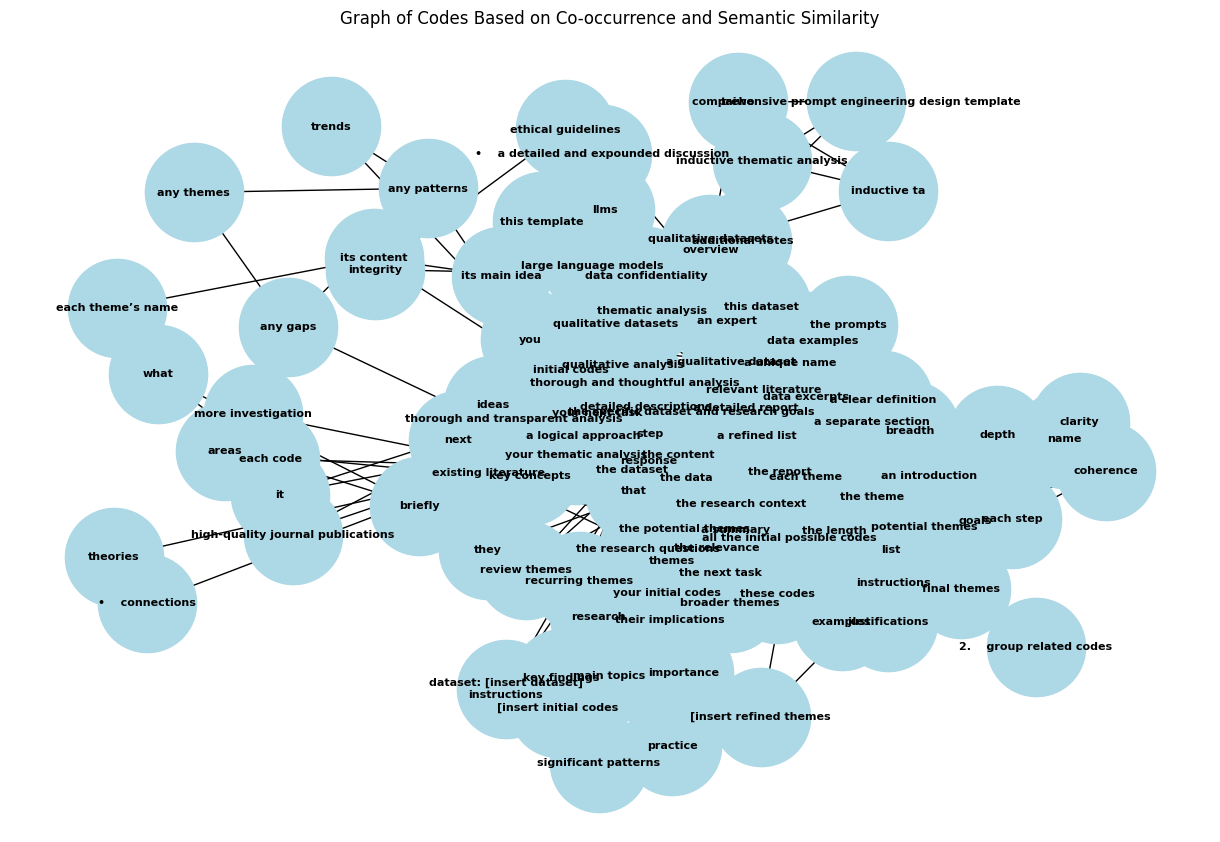

In [9]:
# Import necessary libraries
import spacy
#from collections import defaultdict, deque
from collections import defaultdict
from itertools import combinations

# Define the preprocess_paragraph_to_graph function
# def preprocess_paragraph_to_graph(paragraph, similarity_threshold=0.75):
#     # Load the English language model with medium-sized vectors
#     nlp = spacy.load('en_core_web_md')
#     doc = nlp(paragraph)

#     # Step 1: Extract initial codes with data excerpts
#     initial_codes = {}
#     for sent in doc.sents:
#         for chunk in sent.noun_chunks:
#             code = chunk.text.strip().lower()
#             excerpt = sent.text.strip()
#             if code not in initial_codes:
#                 initial_codes[code] = {'excerpts': [excerpt], 'vector': chunk.vector}
#             else:
#                 initial_codes[code]['excerpts'].append(excerpt)

#     # Step 2: Build graph of codes based on co-occurrence and semantic similarity
#     graph = defaultdict(set)

#     # Co-occurrence in sentences
#     for sent in doc.sents:
#         sent_codes = [chunk.text.strip().lower() for chunk in sent.noun_chunks]
#         for code1, code2 in combinations(sent_codes, 2):
#             if code1 != code2:
#                 graph[code1].add(code2)
#                 graph[code2].add(code1)  # Assuming undirected edges

#     # Semantic similarity
#     codes = list(initial_codes.keys())
#     for i, code1 in enumerate(codes):
#         vector1 = initial_codes[code1]['vector']
#         for code2 in codes[i+1:]:
#             vector2 = initial_codes[code2]['vector']
#             similarity = vector1.dot(vector2) / (vector1.norm() * vector2.norm())
#             if similarity >= similarity_threshold:
#                 graph[code1].add(code2)
#                 graph[code2].add(code1)

#     return initial_codes, graph

def preprocess_paragraph_to_graph(paragraph, similarity_threshold=0.75):
    import spacy
    import numpy as np
    from collections import defaultdict
    from itertools import combinations

    # Load the English language model with medium-sized vectors
    nlp = spacy.load('en_core_web_md')
    doc = nlp(paragraph)

    # Step 1: Extract initial codes with data excerpts
    initial_codes = {}
    for sent in doc.sents:
        for chunk in sent.noun_chunks:
            code = chunk.text.strip().lower()
            excerpt = sent.text.strip()
            if code not in initial_codes:
                initial_codes[code] = {'excerpts': [excerpt], 'vector': chunk.vector}
            else:
                initial_codes[code]['excerpts'].append(excerpt)

    # Step 2: Build graph of codes based on co-occurrence and semantic similarity
    graph = defaultdict(set)

    # Co-occurrence in sentences
    for sent in doc.sents:
        sent_codes = [chunk.text.strip().lower() for chunk in sent.noun_chunks]
        for code1, code2 in combinations(sent_codes, 2):
            if code1 != code2:
                graph[code1].add(code2)
                graph[code2].add(code1)  # Assuming undirected edges

    # Semantic similarity
    codes = list(initial_codes.keys())
    for i, code1 in enumerate(codes):
        vector1 = initial_codes[code1]['vector']
        for code2 in codes[i+1:]:
            vector2 = initial_codes[code2]['vector']
            # Compute cosine similarity using numpy functions
            numerator = np.dot(vector1, vector2)
            denominator = np.linalg.norm(vector1) * np.linalg.norm(vector2)
            if denominator == 0:
                similarity = 0
            else:
                similarity = numerator / denominator
            if similarity >= similarity_threshold:
                graph[code1].add(code2)
                graph[code2].add(code1)

    return initial_codes, graph

# Define the TarjanSCC class to find strongly connected components
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph  # Should be a dictionary with nodes as keys
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.onStack = set()
        self.SCCs = []

        # Preprocess the graph to include all nodes
        self._initialize_nodes()

    def _initialize_nodes(self):
        # Ensure that all nodes referenced in edges are present as keys
        nodes = set(self.graph.keys())
        for edges in self.graph.values():
            nodes.update(edges)
        for node in nodes:
            self.graph.setdefault(node, set())

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.onStack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.onStack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            SCC = []
            while True:
                w = self.stack.pop()
                self.onStack.remove(w)
                SCC.append(w)
                if w == v:
                    break
            self.SCCs.append(SCC)

    def find_sccs(self):
        for v in self.graph:
            if v not in self.indices:
                self.strongconnect(v)
        return self.SCCs

# The dataset (your paragraph)
paragraph = """
TAIWO for Inductive TA: Comprehensive Prompt Engineering Design Template for Inductive Thematic Analysis of Qualitative Datasets
Overview:
This template provides a step-by-step guide for using large language models (LLMs) to perform thematic analysis on qualitative datasets. It follows a logical approach, ensuring thorough and transparent analysis suitable for high-quality journal publications.
Step 1: Get to Know the Data
You are an expert in qualitative analysis. You have a qualitative dataset to analyze. Start by understanding the content of this dataset.
Dataset: [Insert dataset]
Instructions:
1.    Summarize the dataset, including main topics and recurring themes.
2.    Note any patterns or trends you observe.
3.    Identify any gaps or areas that need more investigation.
Response:
Step 2: Create Initial Codes
Now that you understand the dataset, your next task is to create initial codes that represent key concepts and ideas within the data.
Dataset: [Insert dataset]
Instructions:
1.    Search through the length and breadth of the dataset and list all the initial possible codes from the data.
2.    Briefly describe what each code represents.
Response:
Step 3: Identify Themes
With your initial codes ready, the next task is to find broader themes that group these codes. Themes should show significant patterns related to the research questions.
Initial Codes: [Insert initial codes]
Instructions:
1.    Explain why each code is relevant to the dataset.
2.    Group related codes into potential themes.
3.    Name each theme and describe its main idea.
4.    Provide examples from the data that support each theme.
Response:
Step 4: Review Themes
Now, review and refine the potential themes to ensure they accurately reflect the data and are distinct from each other.
Potential Themes: [Insert potential themes]
Instructions:
1.    Check each theme for clarity and coherence. Be as interpretive and thorough as possible.
2.    Decide if any themes should be combined, split, or removed.
3.    Provide a refined list of themes with detailed descriptions.
4.    Include data excerpts that support each theme.
Response:
Step 5: Define and Name Themes
Next, clearly define and name each theme. Each theme should have a unique name and a clear definition.
Refined Themes: [Insert refined themes]
Instructions:
1.    Define each theme clearly, thoroughly and elaborately.
2.    Ensure each theme’s name is concise and representative of its content.
3.    Explain the relevance and importance of each theme in the research context.
Response:
Step 6: Write the Report
Finally, write a detailed report based on your thematic analysis. The report should discuss each theme in depth, supported by data examples and relevant literature.
Final Themes: [Insert final themes]
Instructions:
1.    Write an introduction that outlines the research context and goals.
2.    Discuss each theme in a separate section, including:
•    A clear definition and name of the theme.
•    A detailed and expounded discussion supported by data excerpts.
•    Connections to existing literature and theories.
3.    Conclude with a summary of key findings and their implications for research and practice.
Response:
Additional Notes:
•    The prompts should encourage thorough and thoughtful analysis.
•    Be transparent by including data excerpts and justifications for each step.
•    Follow ethical guidelines to ensure data confidentiality and integrity.
•    Adjust the prompts as needed to fit the specific dataset and research goals.
"""

# Step 1: Preprocess the paragraph to get initial codes and the graph
initial_codes, graph = preprocess_paragraph_to_graph(paragraph)

# Step 2: Apply Tarjan's algorithm to find thematic clusters (strongly connected components)
tarjan = TarjanSCC(graph)
sccs = tarjan.find_sccs()

# Step 3: Analyze and output the thematic clusters
print("Identified Themes:")
for idx, scc in enumerate(sccs):
    print(f"\nTheme {idx + 1}:")
    for code in scc:
        print(f"- Code: {code}")
        print("  Excerpts:")
        for excerpt in initial_codes[code]['excerpts']:
            print(f"    • {excerpt}")
        print()

# Optional: Visualize the graph (requires networkx and matplotlib)
# Uncomment the following code if you wish to visualize the graph.

import networkx as nx
import matplotlib.pyplot as plt

# Create a networkx graph from the adjacency list
G = nx.Graph()
for node, neighbors in graph.items():
    for neighbor in neighbors:
        G.add_edge(node, neighbor)

# Draw the graph
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.5)
nx.draw(G, pos, with_labels=True, node_size=5000, node_color='lightblue', font_size=8, font_weight='bold')
plt.title("Graph of Codes Based on Co-occurrence and Semantic Similarity")
plt.show()


Identified Themes:

Theme 1:
- Code: excellent written and verbal communication skills
  Excerpts:
    • Excellent written and verbal communication skills.

- Code: powerpoint
  Excerpts:
    • Experience with Microsoft office suite – Outlook, Word, Excel, PowerPoint.

- Code: microsoft office suite
  Excerpts:
    • Experience with Microsoft office suite – Outlook, Word, Excel, PowerPoint.

- Code: outlook
  Excerpts:
    • Experience with Microsoft office suite – Outlook, Word, Excel, PowerPoint.

- Code: excel
  Excerpts:
    • Experience with Microsoft office suite – Outlook, Word, Excel, PowerPoint.

- Code: word
  Excerpts:
    • Experience with Microsoft office suite – Outlook, Word, Excel, PowerPoint.

- Code: drives
  Excerpts:
    • Some legacy platforms include Delta, Mitsubishi, and Citect.
Experience with AC and DC motors, including drives.

- Code: citect
  Excerpts:
    • Some legacy platforms include Delta, Mitsubishi, and Citect.
Experience with AC and DC motors, inclu

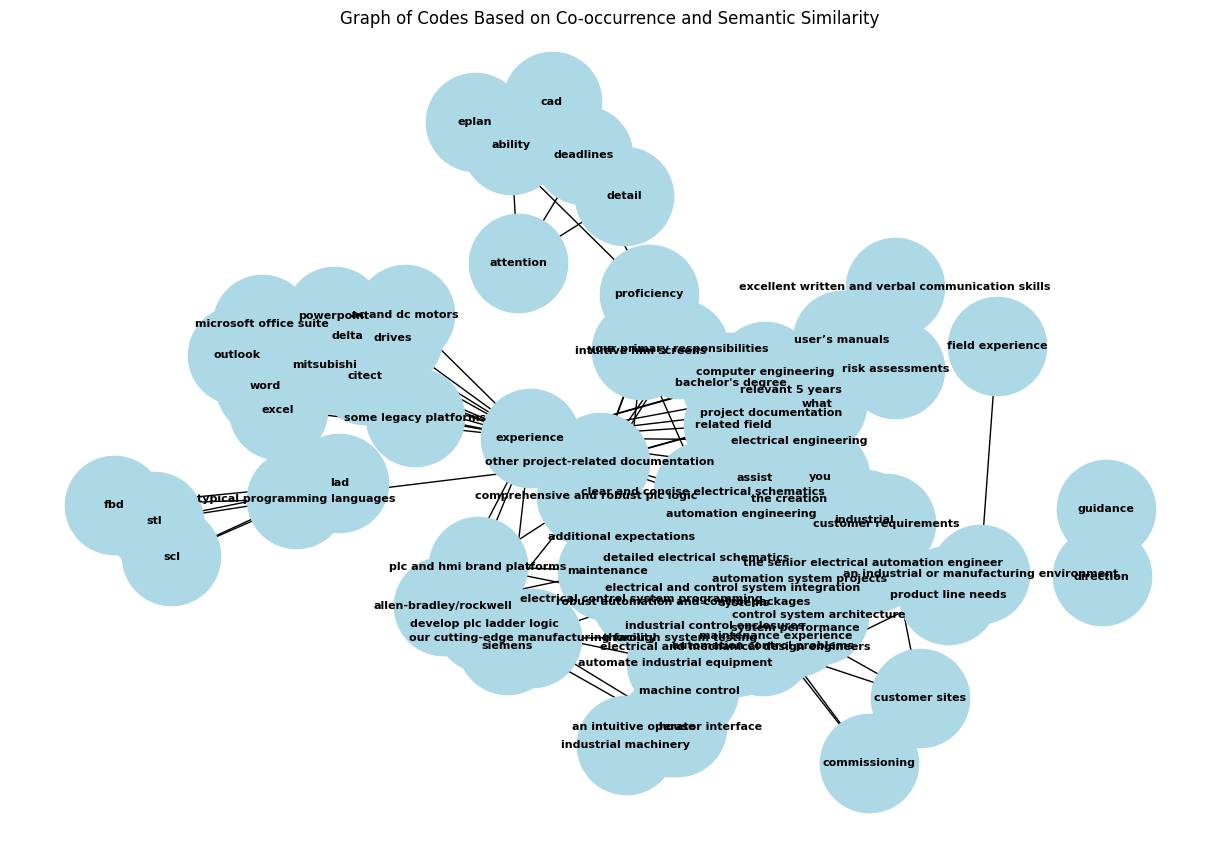

In [10]:
# Import necessary libraries
import spacy
#from collections import defaultdict, deque
from collections import defaultdict
from itertools import combinations

def preprocess_paragraph_to_graph(paragraph, similarity_threshold=0.75):
    import spacy
    import numpy as np
    from collections import defaultdict
    from itertools import combinations

    # Load the English language model with medium-sized vectors
    nlp = spacy.load('en_core_web_md')
    doc = nlp(paragraph)

    # Step 1: Extract initial codes with data excerpts
    initial_codes = {}
    for sent in doc.sents:
        for chunk in sent.noun_chunks:
            code = chunk.text.strip().lower()
            excerpt = sent.text.strip()
            if code not in initial_codes:
                initial_codes[code] = {'excerpts': [excerpt], 'vector': chunk.vector}
            else:
                initial_codes[code]['excerpts'].append(excerpt)

    # Step 2: Build graph of codes based on co-occurrence and semantic similarity
    graph = defaultdict(set)

    # Co-occurrence in sentences
    for sent in doc.sents:
        sent_codes = [chunk.text.strip().lower() for chunk in sent.noun_chunks]
        for code1, code2 in combinations(sent_codes, 2):
            if code1 != code2:
                graph[code1].add(code2)
                graph[code2].add(code1)  # Assuming undirected edges

    # Semantic similarity
    codes = list(initial_codes.keys())
    for i, code1 in enumerate(codes):
        vector1 = initial_codes[code1]['vector']
        for code2 in codes[i+1:]:
            vector2 = initial_codes[code2]['vector']
            # Compute cosine similarity using numpy functions
            numerator = np.dot(vector1, vector2)
            denominator = np.linalg.norm(vector1) * np.linalg.norm(vector2)
            if denominator == 0:
                similarity = 0
            else:
                similarity = numerator / denominator
            if similarity >= similarity_threshold:
                graph[code1].add(code2)
                graph[code2].add(code1)

    return initial_codes, graph

# Define the TarjanSCC class to find strongly connected components
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph  # Should be a dictionary with nodes as keys
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.onStack = set()
        self.SCCs = []

        # Preprocess the graph to include all nodes
        self._initialize_nodes()

    def _initialize_nodes(self):
        # Ensure that all nodes referenced in edges are present as keys
        nodes = set(self.graph.keys())
        for edges in self.graph.values():
            nodes.update(edges)
        for node in nodes:
            self.graph.setdefault(node, set())

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.onStack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.onStack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            SCC = []
            while True:
                w = self.stack.pop()
                self.onStack.remove(w)
                SCC.append(w)
                if w == v:
                    break
            self.SCCs.append(SCC)

    def find_sccs(self):
        for v in self.graph:
            if v not in self.indices:
                self.strongconnect(v)
        return self.SCCs

# The dataset (your paragraph)
paragraph = """
As the Senior Electrical Automation Engineer – Industrial, you will be successful in implementing automation system projects by understanding customer requirements, product line needs, and control system architecture. Your primary responsibilities will include developing comprehensive and robust PLC logic, intuitive HMI screens, clear and concise electrical schematics, and other project-related documentation. Additional expectations include coordinating thorough system testing and debugging in-house at our cutting-edge manufacturing facility.
Develop PLC ladder logic to automate industrial equipment and create an intuitive operator interface. Typical programming languages include LAD, FBD, STL and SCL. LAD/FBD experience is required.
Assist and collaborate in the creation and maintenance of detailed electrical schematics for industrial control enclosures and systems.
Troubleshoot automation control problems and improve system performance at customer sites.
Collaborate with electrical and mechanical design engineers to develop robust automation and control packages for industrial machinery and machine control.
Assist and collaborate in the creation of project documentation such as risk assessments and user’s manuals.
What You Will Bring:
Bachelor's degree in related field such as Automation Engineering, Electrical Engineering, Computer Engineering, etc., or at least equivalent relevant 5 years of experience.
Experience with electrical control system programming and maintenance, specifically with PLC and HMI brand platforms; Siemens and Allen-Bradley/Rockwell. Some legacy platforms include Delta, Mitsubishi, and Citect.
Experience with AC and DC motors, including drives.
Electrical and control system integration, commissioning, and maintenance experience.
Proficiency in CAD and EPLAN is preferred, but not required.
Field experience in an industrial or manufacturing environment preferred, not required.
Ability to travel internationally preferred, not required.
Ability to multitask, while maintaining attention to detail and deadlines.
Experience with Microsoft office suite – Outlook, Word, Excel, PowerPoint.
Excellent written and verbal communication skills.
Team oriented and collaborative.
Self-motivated, while also accepting guidance and direction.
"""

# Step 1: Preprocess the paragraph to get initial codes and the graph
initial_codes, graph = preprocess_paragraph_to_graph(paragraph)

# Step 2: Apply Tarjan's algorithm to find thematic clusters (strongly connected components)
tarjan = TarjanSCC(graph)
sccs = tarjan.find_sccs()

# Step 3: Analyze and output the thematic clusters
print("Identified Themes:")
for idx, scc in enumerate(sccs):
    print(f"\nTheme {idx + 1}:")
    for code in scc:
        print(f"- Code: {code}")
        print("  Excerpts:")
        for excerpt in initial_codes[code]['excerpts']:
            print(f"    • {excerpt}")
        print()

# Optional: Visualize the graph (requires networkx and matplotlib)
# Uncomment the following code if you wish to visualize the graph.

import networkx as nx
import matplotlib.pyplot as plt

# Create a networkx graph from the adjacency list
G = nx.Graph()
for node, neighbors in graph.items():
    for neighbor in neighbors:
        G.add_edge(node, neighbor)

# Draw the graph
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.5)
nx.draw(G, pos, with_labels=True, node_size=5000, node_color='lightblue', font_size=8, font_weight='bold')
plt.title("Graph of Codes Based on Co-occurrence and Semantic Similarity")
plt.show()


Identified Themes:

Theme 1:
- Code: the hub podcast
  Excerpts:
    • Raw transcription of speaking notes for The Hub podcast.

- Code: speaking notes
  Excerpts:
    • Raw transcription of speaking notes for The Hub podcast.

- Code: raw transcription
  Excerpts:
    • Raw transcription of speaking notes for The Hub podcast.


Theme 2:
- Code: activity system
  Excerpts:
    • All of these are designed, and we can approach this from a design perspective, we can also analyze those spaces from a design perspective or from a user of for example of task analysis, perspective, and activity system perspective

- Code: these
  Excerpts:
    • All of these are designed, and we can approach this from a design perspective, we can also analyze those spaces from a design perspective or from a user of for example of task analysis, perspective, and activity system perspective

- Code: all
  Excerpts:
    • All of these are designed, and we can approach this from a design perspective, we can also a

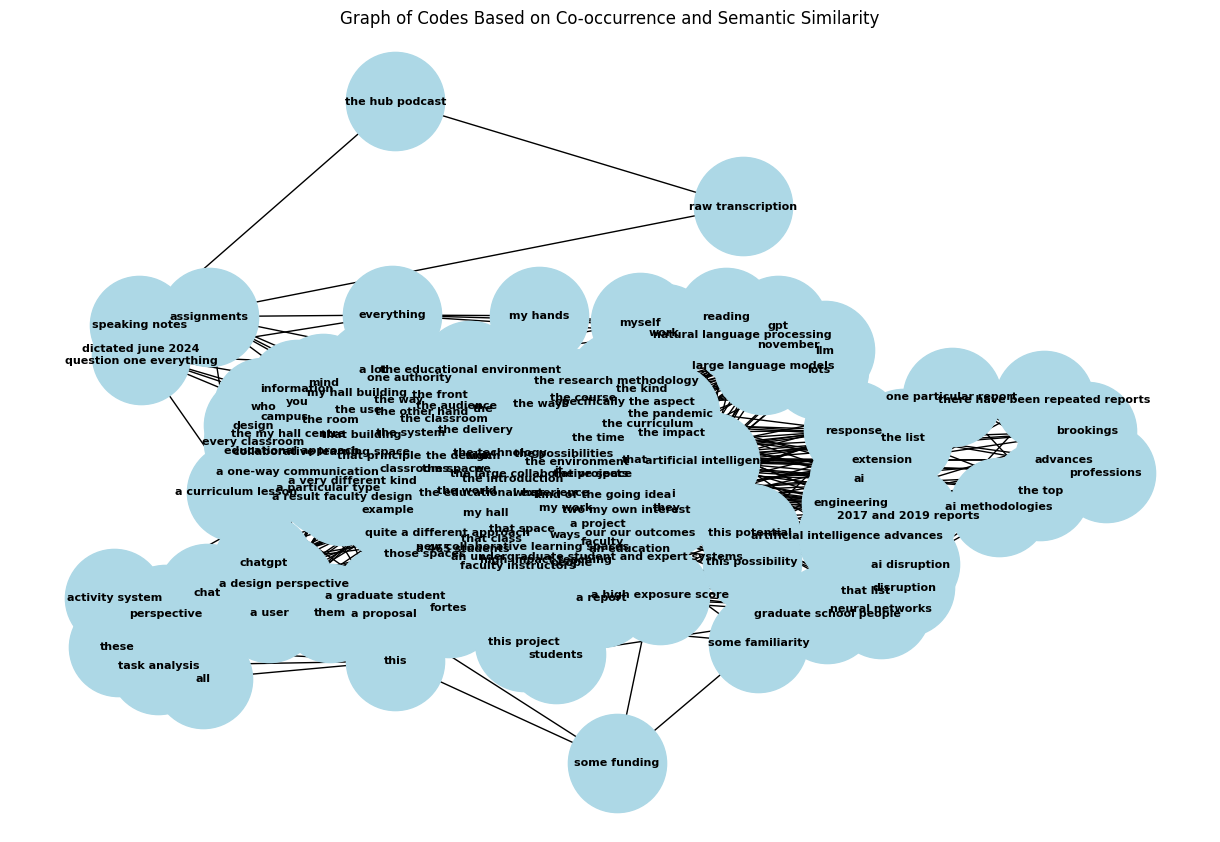

In [13]:
# Import necessary libraries
import spacy
#from collections import defaultdict, deque
from collections import defaultdict
from itertools import combinations

def preprocess_paragraph_to_graph(paragraph, similarity_threshold=0.75):
    import spacy
    import numpy as np
    from collections import defaultdict
    from itertools import combinations

    # Load the English language model with medium-sized vectors
    nlp = spacy.load('en_core_web_md')
    doc = nlp(paragraph)

    # Step 1: Extract initial codes with data excerpts
    initial_codes = {}
    for sent in doc.sents:
        for chunk in sent.noun_chunks:
            code = chunk.text.strip().lower()
            excerpt = sent.text.strip()
            if code not in initial_codes:
                initial_codes[code] = {'excerpts': [excerpt], 'vector': chunk.vector}
            else:
                initial_codes[code]['excerpts'].append(excerpt)

    # Step 2: Build graph of codes based on co-occurrence and semantic similarity
    graph = defaultdict(set)

    # Co-occurrence in sentences
    for sent in doc.sents:
        sent_codes = [chunk.text.strip().lower() for chunk in sent.noun_chunks]
        for code1, code2 in combinations(sent_codes, 2):
            if code1 != code2:
                graph[code1].add(code2)
                graph[code2].add(code1)  # Assuming undirected edges

    # Semantic similarity
    codes = list(initial_codes.keys())
    for i, code1 in enumerate(codes):
        vector1 = initial_codes[code1]['vector']
        for code2 in codes[i+1:]:
            vector2 = initial_codes[code2]['vector']
            # Compute cosine similarity using numpy functions
            numerator = np.dot(vector1, vector2)
            denominator = np.linalg.norm(vector1) * np.linalg.norm(vector2)
            if denominator == 0:
                similarity = 0
            else:
                similarity = numerator / denominator
            if similarity >= similarity_threshold:
                graph[code1].add(code2)
                graph[code2].add(code1)

    return initial_codes, graph

# Define the TarjanSCC class to find strongly connected components
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph  # Should be a dictionary with nodes as keys
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.onStack = set()
        self.SCCs = []

        # Preprocess the graph to include all nodes
        self._initialize_nodes()

    def _initialize_nodes(self):
        # Ensure that all nodes referenced in edges are present as keys
        nodes = set(self.graph.keys())
        for edges in self.graph.values():
            nodes.update(edges)
        for node in nodes:
            self.graph.setdefault(node, set())

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.onStack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.onStack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            SCC = []
            while True:
                w = self.stack.pop()
                self.onStack.remove(w)
                SCC.append(w)
                if w == v:
                    break
            self.SCCs.append(SCC)

    def find_sccs(self):
        for v in self.graph:
            if v not in self.indices:
                self.strongconnect(v)
        return self.SCCs

# The dataset (your paragraph)
paragraph = """
Raw transcription of speaking notes for The Hub podcast. Dictated June 2024
Question one everything about the educational environment is actually designed everything from the way in which we designed classrooms to the way in which we design a curriculum lesson plans the way in which we design assignments. All of these are designed, and we can approach this from a design perspective, we can also analyze those spaces from a design perspective or from a user of for example of task analysis, perspective, and activity system perspective so if we think about the ways in which we design, for example, fortes into classrooms afford says means what does the space what does the technology? What does the system that we create suggest is the is the way in which we use the space is the way in which we use the technology the design should suggest the use intuitively if we design classrooms that suggest that there is one authority at the front of the room who is transmitting information to the audience and it's a one-way communication because that's how the room is set up then that suggest a particular type of educational approach if on the other hand, for example, in the my hall centre that we have here on campus my hall building if we design classrooms and every classroom in that building is designed to be collaborative learning space if we design it for collaborative learning space if we have that principle in mind that accordance in mind as we're designing it, then you get a very different kind of designed for the classroom, a different kind of design for the technology, and as a result faculty design. Courses differently, they design the delivery of the course differently to teach effectively in those spaces. It's quite a different approach to learning and an education of the educational experience so in my work one of the projects we've done recently for example is to observe people teaching in that class in the large collaborative space that we have in my hall that seats about a 465 students to observe how faculty are either using the technology or abandoning the technology that we have put into the space to understand how people are interacting with the design of the environment in that space what's working what's not working so that as we go forward and design new collaborative learning spaces, we understand and can use our our outcomes to better predict ways in which we can design classrooms to increase the possibilities of faculty instructors using high impact teaching practises in those spaces question two my own interest in artificial intelligence it goes back to when I was an undergraduate student and expert systems was kind of a very was kind of the going idea at the time and then when I was in graduate school people were experimenting with neural networks but most recently in 2019 a report came out in 2017 and 2019 reports came out that suggested that engineering was a potentially vulnerable to disruption by artificial intelligence advances and it had what was called is called a high exposure score to AI disruption. I am there was one particular report by Brookings in 2019 that suggested that engineering was near the top of the list of professions that might be severely impacted by advances in artificial intelligence. That was relatively new and there have been repeated reports since then they have placed engineering near the top of that list and so I began working on developing a project that would use AI to actually explore AI methodologies to actually explore that this possibility and the pandemic intervened but very quickly. I got back onto that and started a project in 2021 that was looking at or starting to look at how we could better understand the impact of AI on engineering and by extension the way in which the curriculum and in engineering should be adjusted in response to this potential and in 2020 of 2022 I I wrote a proposal to get some funding for this. It was turned down. I resubmitted in 2023 and it's been funded and I have a graduate student to graduate students actually now working on this project they started one of them started back before the introduction of ChatGPT to the world and so I already had some familiarity with the technology before chat. GPT was released in November 2022, but very quickly once it was released, I started doing lots of reading and lots of work to bring myself up to speed on specifically the aspect of artificial intelligence related to large language models because it was clear that I mean the kind of work I was doing was related to natural language processing, but really wasn't necessarily didn't necessarily require LLM although now we're incorporating that into the research methodology were using but at the time I I just read everything I could get my hands on and did a lot of work to bring myself up to speed on the technology.
"""

# Step 1: Preprocess the paragraph to get initial codes and the graph
initial_codes, graph = preprocess_paragraph_to_graph(paragraph)

# Step 2: Apply Tarjan's algorithm to find thematic clusters (strongly connected components)
tarjan = TarjanSCC(graph)
sccs = tarjan.find_sccs()

# Step 3: Analyze and output the thematic clusters
print("Identified Themes:")
for idx, scc in enumerate(sccs):
    print(f"\nTheme {idx + 1}:")
    for code in scc:
        print(f"- Code: {code}")
        print("  Excerpts:")
        for excerpt in initial_codes[code]['excerpts']:
            print(f"    • {excerpt}")
        print()

# Optional: Visualize the graph (requires networkx and matplotlib)
# Uncomment the following code if you wish to visualize the graph.

import networkx as nx
import matplotlib.pyplot as plt

# Create a networkx graph from the adjacency list
G = nx.Graph()
for node, neighbors in graph.items():
    for neighbor in neighbors:
        G.add_edge(node, neighbor)

# Draw the graph
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.5)
nx.draw(G, pos, with_labels=True, node_size=5000, node_color='lightblue', font_size=8, font_weight='bold')
plt.title("Graph of Codes Based on Co-occurrence and Semantic Similarity")
plt.show()


In [11]:
# Import necessary libraries
import spacy
from collections import defaultdict
from itertools import combinations
import numpy as np

# Load SpaCy's English language model with medium-sized vectors
nlp = spacy.load('en_core_web_md')

def preprocess_paragraph_to_graph(paragraph, similarity_threshold=0.5):
    """
    Preprocess the paragraph to extract initial codes with data excerpts,
    and group them into themes based on syntactic and semantic similarities.
    """
    # Data Preparation and Preprocessing
    # Normalize text: lowercase, remove punctuation
    doc = nlp(paragraph.lower())

    # Lemmatization and Tokenization
    lemmatized_sentences = []
    for sent in doc.sents:
        tokens = [token.lemma_ for token in sent if not token.is_punct]
        lemmatized_sentences.append(tokens)

    # Extract initial codes with data excerpts
    initial_codes = {}
    for sent in doc.sents:
        for chunk in sent.noun_chunks:
            # Clean code: lemmatize and remove stop words
            code_tokens = [token.lemma_ for token in chunk if not token.is_stop and not token.is_punct]
            code = ' '.join(code_tokens).strip()
            if code == '':
                continue
            excerpt = sent.text.strip()
            if code not in initial_codes:
                initial_codes[code] = {'excerpts': [excerpt], 'vector': nlp(code).vector}
            else:
                initial_codes[code]['excerpts'].append(excerpt)

    # Build graph of codes based on syntactic and semantic similarity
    graph = defaultdict(set)

    codes = list(initial_codes.keys())
    code_vectors = {code: initial_codes[code]['vector'] for code in codes}

    # Syntactic Analysis: Extract dependency triples
    code_svo = {}
    for code in codes:
        doc_code = nlp(code)
        svo_triples = []
        for token in doc_code:
            if token.dep_ in ('nsubj', 'nsubjpass'):
                subject = token.text
                verb = token.head.text
                obj = None
                for child in token.head.children:
                    if child.dep_ == 'dobj':
                        obj = child.text
                        break
                if obj:
                    svo_triples.append((subject, verb, obj))
        code_svo[code] = svo_triples

    # Compute syntactic similarity (SynSim) based on matching SVO triples
    syntactic_similarities = {}
    for code1, code2 in combinations(codes, 2):
        triples1 = set(code_svo.get(code1, []))
        triples2 = set(code_svo.get(code2, []))
        total_triples = len(triples1) + len(triples2)
        if total_triples == 0:
            syn_sim = 0
        else:
            matching_triples = triples1.intersection(triples2)
            syn_sim = (2 * len(matching_triples)) / total_triples  # F1 Score
        syntactic_similarities[(code1, code2)] = syn_sim

    # Semantic Analysis: Compute semantic similarity (SemSim)
    semantic_similarities = {}
    for code1, code2 in combinations(codes, 2):
        vector1 = code_vectors[code1]
        vector2 = code_vectors[code2]
        numerator = np.dot(vector1, vector2)
        denominator = np.linalg.norm(vector1) * np.linalg.norm(vector2)
        if denominator == 0:
            sem_sim = 0
        else:
            sem_sim = numerator / denominator
        semantic_similarities[(code1, code2)] = sem_sim

    # Sentence Pattern Analysis: Identify and compare sentence patterns
    code_patterns = {}
    for code in codes:
        doc_code = nlp(code)
        patterns = []
        for token in doc_code:
            if not token.is_punct and not token.is_space:
                patterns.append(token.pos_)
        pattern = '-'.join(patterns)
        code_patterns[code] = pattern

    pattern_similarities = {}
    for code1, code2 in combinations(codes, 2):
        pattern1 = code_patterns.get(code1, '')
        pattern2 = code_patterns.get(code2, '')
        if pattern1 == '' or pattern2 == '':
            pat_sim = 0
        elif pattern1 == pattern2:
            pat_sim = 1
        else:
            pat_sim = 0
        pattern_similarities[(code1, code2)] = pat_sim

    # Metric Development: Combine similarities into a combined similarity score
    combined_similarities = {}
    alpha, beta, gamma = 0.3, 0.5, 0.2  # Weights for SynSim, SemSim, PatSim
    for code1, code2 in combinations(codes, 2):
        syn_sim = syntactic_similarities.get((code1, code2), 0)
        sem_sim = semantic_similarities.get((code1, code2), 0)
        pat_sim = pattern_similarities.get((code1, code2), 0)
        comb_sim = alpha * syn_sim + beta * sem_sim + gamma * pat_sim

        # Normalization Factors (Length and Complexity)
        len_diff = abs(len(code1.split()) - len(code2.split()))
        avg_len = (len(code1.split()) + len(code2.split())) / 2
        if avg_len == 0:
            lnf = 1
        else:
            lnf = 2 / (1 + np.exp(-len_diff / avg_len))

        unique_words1 = len(set(code1.split()))
        unique_words2 = len(set(code2.split()))
        unique_diff = abs(unique_words1 - unique_words2)
        avg_unique = (unique_words1 + unique_words2) / 2
        if avg_unique == 0:
            cnf = 1
        else:
            cnf = 1 / (1 + np.exp(-unique_diff / avg_unique))

        final_score = comb_sim * lnf * cnf

        if final_score >= similarity_threshold:
            graph[code1].add(code2)
            graph[code2].add(code1)

        combined_similarities[(code1, code2)] = final_score

    return initial_codes, graph

# Define the TarjanSCC class to find strongly connected components
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph  # Should be a dictionary with nodes as keys
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.onStack = set()
        self.SCCs = []

        # Preprocess the graph to include all nodes
        self._initialize_nodes()

    def _initialize_nodes(self):
        # Ensure that all nodes referenced in edges are present as keys
        nodes = set(self.graph.keys())
        for edges in self.graph.values():
            nodes.update(edges)
        for node in nodes:
            self.graph.setdefault(node, set())

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.onStack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.onStack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            SCC = []
            while True:
                w = self.stack.pop()
                self.onStack.remove(w)
                SCC.append(w)
                if w == v:
                    break
            self.SCCs.append(SCC)

    def find_sccs(self):
        for v in list(self.graph.keys()):
            if v not in self.indices:
                self.strongconnect(v)
        return self.SCCs

# The dataset (your paragraph)
paragraph = """
As the Senior Electrical Automation Engineer – Industrial, you will be successful in implementing automation system projects by understanding customer requirements, product line needs, and control system architecture. Your primary responsibilities will include developing comprehensive and robust PLC logic, intuitive HMI screens, clear and concise electrical schematics, and other project-related documentation. Additional expectations include coordinating thorough system testing and debugging in-house at our cutting-edge manufacturing facility.
Develop PLC ladder logic to automate industrial equipment and create an intuitive operator interface. Typical programming languages include LAD, FBD, STL and SCL. LAD/FBD experience is required.
Assist and collaborate in the creation and maintenance of detailed electrical schematics for industrial control enclosures and systems.
Troubleshoot automation control problems and improve system performance at customer sites.
Collaborate with electrical and mechanical design engineers to develop robust automation and control packages for industrial machinery and machine control.
Assist and collaborate in the creation of project documentation such as risk assessments and user’s manuals.
What You Will Bring:
Bachelor's degree in related field such as Automation Engineering, Electrical Engineering, Computer Engineering, etc., or at least equivalent relevant 5 years of experience.
Experience with electrical control system programming and maintenance, specifically with PLC and HMI brand platforms; Siemens and Allen-Bradley/Rockwell. Some legacy platforms include Delta, Mitsubishi, and Citect.
Experience with AC and DC motors, including drives.
Electrical and control system integration, commissioning, and maintenance experience.
Proficiency in CAD and EPLAN is preferred, but not required.
Field experience in an industrial or manufacturing environment preferred, not required.
Ability to travel internationally preferred, not required.
Ability to multitask, while maintaining attention to detail and deadlines.
Experience with Microsoft office suite – Outlook, Word, Excel, PowerPoint.
Excellent written and verbal communication skills.
Team oriented and collaborative.
Self-motivated, while also accepting guidance and direction.
"""

# Step 1: Preprocess the paragraph to get initial codes and the graph
initial_codes, graph = preprocess_paragraph_to_graph(paragraph)

# Step 2: Apply Tarjan's algorithm to find thematic clusters (strongly connected components)
tarjan = TarjanSCC(graph)
sccs = tarjan.find_sccs()

# Step 3: Analyze and output the thematic clusters
print("Identified Themes:")
for idx, scc in enumerate(sccs):
    print(f"\nTheme {idx + 1}:")
    for code in scc:
        print(f"- Code: {code}")
        print("  Excerpts:")
        for excerpt in initial_codes[code]['excerpts']:
            print(f"    • {excerpt}")
        print()


Identified Themes:

Theme 1:
- Code: electrical control system programming
  Excerpts:
    • what you will bring:
bachelor's degree in related field such as automation engineering, electrical engineering, computer engineering, etc., or at least equivalent relevant 5 years of experience.
experience with electrical control system programming and maintenance, specifically with plc and hmi brand platforms; siemens and allen-bradley/rockwell.

- Code: electrical control system integration
  Excerpts:
    • some legacy platforms include delta, mitsubishi, and citect.
experience with ac and dc motors, including drives.
electrical and control system integration, commissioning, and maintenance experience.
proficiency in cad and eplan is preferred, but not required.
field experience in an industrial or manufacturing environment preferred, not required.
ability to travel internationally preferred, not required.
ability to multitask, while maintaining attention to detail and deadlines.
experience 

In [12]:
# Import necessary libraries
import spacy
from collections import defaultdict
from itertools import combinations
import numpy as np

# Load SpaCy's English language model with medium-sized vectors
nlp = spacy.load('en_core_web_md')

def preprocess_paragraph_to_graph(paragraph, similarity_threshold=0.5):
    """
    Preprocess the paragraph to extract initial codes with data excerpts,
    and group them into themes based on syntactic and semantic similarities.
    """
    # Data Preparation and Preprocessing
    # Normalize text: lowercase, remove punctuation
    doc = nlp(paragraph.lower())

    # Lemmatization and Tokenization
    lemmatized_sentences = []
    for sent in doc.sents:
        tokens = [token.lemma_ for token in sent if not token.is_punct]
        lemmatized_sentences.append(tokens)

    # Extract initial codes with data excerpts
    initial_codes = {}
    for sent in doc.sents:
        for chunk in sent.noun_chunks:
            # Clean code: lemmatize and remove stop words
            code_tokens = [token.lemma_ for token in chunk if not token.is_stop and not token.is_punct]
            code = ' '.join(code_tokens).strip()
            if code == '':
                continue
            excerpt = sent.text.strip()
            if code not in initial_codes:
                initial_codes[code] = {'excerpts': [excerpt], 'vector': nlp(code).vector}
            else:
                initial_codes[code]['excerpts'].append(excerpt)

    # Build graph of codes based on syntactic and semantic similarity
    graph = defaultdict(set)

    codes = list(initial_codes.keys())
    code_vectors = {code: initial_codes[code]['vector'] for code in codes}

    # Syntactic Analysis: Extract dependency triples
    code_svo = {}
    for code in codes:
        doc_code = nlp(code)
        svo_triples = []
        for token in doc_code:
            if token.dep_ in ('nsubj', 'nsubjpass'):
                subject = token.text
                verb = token.head.text
                obj = None
                for child in token.head.children:
                    if child.dep_ == 'dobj':
                        obj = child.text
                        break
                if obj:
                    svo_triples.append((subject, verb, obj))
        code_svo[code] = svo_triples

    # Compute syntactic similarity (SynSim) based on matching SVO triples
    syntactic_similarities = {}
    for code1, code2 in combinations(codes, 2):
        triples1 = set(code_svo.get(code1, []))
        triples2 = set(code_svo.get(code2, []))
        total_triples = len(triples1) + len(triples2)
        if total_triples == 0:
            syn_sim = 0
        else:
            matching_triples = triples1.intersection(triples2)
            syn_sim = (2 * len(matching_triples)) / total_triples  # F1 Score
        syntactic_similarities[(code1, code2)] = syn_sim

    # Semantic Analysis: Compute semantic similarity (SemSim)
    semantic_similarities = {}
    for code1, code2 in combinations(codes, 2):
        vector1 = code_vectors[code1]
        vector2 = code_vectors[code2]
        numerator = np.dot(vector1, vector2)
        denominator = np.linalg.norm(vector1) * np.linalg.norm(vector2)
        if denominator == 0:
            sem_sim = 0
        else:
            sem_sim = numerator / denominator
        semantic_similarities[(code1, code2)] = sem_sim

    # Sentence Pattern Analysis: Identify and compare sentence patterns
    code_patterns = {}
    for code in codes:
        doc_code = nlp(code)
        patterns = []
        for token in doc_code:
            if not token.is_punct and not token.is_space:
                patterns.append(token.pos_)
        pattern = '-'.join(patterns)
        code_patterns[code] = pattern

    pattern_similarities = {}
    for code1, code2 in combinations(codes, 2):
        pattern1 = code_patterns.get(code1, '')
        pattern2 = code_patterns.get(code2, '')
        if pattern1 == '' or pattern2 == '':
            pat_sim = 0
        elif pattern1 == pattern2:
            pat_sim = 1
        else:
            pat_sim = 0
        pattern_similarities[(code1, code2)] = pat_sim

    # Metric Development: Combine similarities into a combined similarity score
    combined_similarities = {}
    alpha, beta, gamma = 0.3, 0.5, 0.2  # Weights for SynSim, SemSim, PatSim
    for code1, code2 in combinations(codes, 2):
        syn_sim = syntactic_similarities.get((code1, code2), 0)
        sem_sim = semantic_similarities.get((code1, code2), 0)
        pat_sim = pattern_similarities.get((code1, code2), 0)
        comb_sim = alpha * syn_sim + beta * sem_sim + gamma * pat_sim

        # Normalization Factors (Length and Complexity)
        len_diff = abs(len(code1.split()) - len(code2.split()))
        avg_len = (len(code1.split()) + len(code2.split())) / 2
        if avg_len == 0:
            lnf = 1
        else:
            lnf = 2 / (1 + np.exp(-len_diff / avg_len))

        unique_words1 = len(set(code1.split()))
        unique_words2 = len(set(code2.split()))
        unique_diff = abs(unique_words1 - unique_words2)
        avg_unique = (unique_words1 + unique_words2) / 2
        if avg_unique == 0:
            cnf = 1
        else:
            cnf = 1 / (1 + np.exp(-unique_diff / avg_unique))

        final_score = comb_sim * lnf * cnf

        if final_score >= similarity_threshold:
            graph[code1].add(code2)
            graph[code2].add(code1)

        combined_similarities[(code1, code2)] = final_score

    return initial_codes, graph

# Define the TarjanSCC class to find strongly connected components
class TarjanSCC:
    def __init__(self, graph):
        self.graph = graph  # Should be a dictionary with nodes as keys
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.onStack = set()
        self.SCCs = []

        # Preprocess the graph to include all nodes
        self._initialize_nodes()

    def _initialize_nodes(self):
        # Ensure that all nodes referenced in edges are present as keys
        nodes = set(self.graph.keys())
        for edges in self.graph.values():
            nodes.update(edges)
        for node in nodes:
            self.graph.setdefault(node, set())

    def strongconnect(self, v):
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.onStack.add(v)

        for w in self.graph[v]:
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.onStack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        if self.lowlink[v] == self.indices[v]:
            SCC = []
            while True:
                w = self.stack.pop()
                self.onStack.remove(w)
                SCC.append(w)
                if w == v:
                    break
            self.SCCs.append(SCC)

    def find_sccs(self):
        for v in list(self.graph.keys()):
            if v not in self.indices:
                self.strongconnect(v)
        return self.SCCs

# The dataset (your paragraph)
paragraph = """
Raw transcription of speaking notes for The Hub podcast. Dictated June 2024
Question one everything about the educational environment is actually designed everything from the way in which we designed classrooms to the way in which we design a curriculum lesson plans the way in which we design assignments. All of these are designed, and we can approach this from a design perspective, we can also analyze those spaces from a design perspective or from a user of for example of task analysis, perspective, and activity system perspective so if we think about the ways in which we design, for example, fortes into classrooms afford says means what does the space what does the technology? What does the system that we create suggest is the is the way in which we use the space is the way in which we use the technology the design should suggest the use intuitively if we design classrooms that suggest that there is one authority at the front of the room who is transmitting information to the audience and it's a one-way communication because that's how the room is set up then that suggest a particular type of educational approach if on the other hand, for example, in the my hall centre that we have here on campus my hall building if we design classrooms and every classroom in that building is designed to be collaborative learning space if we design it for collaborative learning space if we have that principle in mind that accordance in mind as we're designing it, then you get a very different kind of designed for the classroom, a different kind of design for the technology, and as a result faculty design. Courses differently, they design the delivery of the course differently to teach effectively in those spaces. It's quite a different approach to learning and an education of the educational experience so in my work one of the projects we've done recently for example is to observe people teaching in that class in the large collaborative space that we have in my hall that seats about a 465 students to observe how faculty are either using the technology or abandoning the technology that we have put into the space to understand how people are interacting with the design of the environment in that space what's working what's not working so that as we go forward and design new collaborative learning spaces, we understand and can use our our outcomes to better predict ways in which we can design classrooms to increase the possibilities of faculty instructors using high impact teaching practises in those spaces question two my own interest in artificial intelligence it goes back to when I was an undergraduate student and expert systems was kind of a very was kind of the going idea at the time and then when I was in graduate school people were experimenting with neural networks but most recently in 2019 a report came out in 2017 and 2019 reports came out that suggested that engineering was a potentially vulnerable to disruption by artificial intelligence advances and it had what was called is called a high exposure score to AI disruption. I am there was one particular report by Brookings in 2019 that suggested that engineering was near the top of the list of professions that might be severely impacted by advances in artificial intelligence. That was relatively new and there have been repeated reports since then they have placed engineering near the top of that list and so I began working on developing a project that would use AI to actually explore AI methodologies to actually explore that this possibility and the pandemic intervened but very quickly. I got back onto that and started a project in 2021 that was looking at or starting to look at how we could better understand the impact of AI on engineering and by extension the way in which the curriculum and in engineering should be adjusted in response to this potential and in 2020 of 2022 I I wrote a proposal to get some funding for this. It was turned down. I resubmitted in 2023 and it's been funded and I have a graduate student to graduate students actually now working on this project they started one of them started back before the introduction of ChatGPT to the world and so I already had some familiarity with the technology before chat. GPT was released in November 2022, but very quickly once it was released, I started doing lots of reading and lots of work to bring myself up to speed on specifically the aspect of artificial intelligence related to large language models because it was clear that I mean the kind of work I was doing was related to natural language processing, but really wasn't necessarily didn't necessarily require LLM although now we're incorporating that into the research methodology were using but at the time I I just read everything I could get my hands on and did a lot of work to bring myself up to speed on the technology.
"""

# Step 1: Preprocess the paragraph to get initial codes and the graph
initial_codes, graph = preprocess_paragraph_to_graph(paragraph)

# Step 2: Apply Tarjan's algorithm to find thematic clusters (strongly connected components)
tarjan = TarjanSCC(graph)
sccs = tarjan.find_sccs()

# Step 3: Analyze and output the thematic clusters
print("Identified Themes:")
for idx, scc in enumerate(sccs):
    print(f"\nTheme {idx + 1}:")
    for code in scc:
        print(f"- Code: {code}")
        print("  Excerpts:")
        for excerpt in initial_codes[code]['excerpts']:
            print(f"    • {excerpt}")
        print()


Identified Themes:


In [ ]:
# Import required libraries
from collections import defaultdict, deque
import time
import random
import pandas as pd

# Function to generate a large random graph (can be cyclic or acyclic)
def generate_large_graph(num_nodes, max_edges_per_node, acyclic=True):
    """
    Generates a large random directed graph.

    Parameters:
    - num_nodes (int): Number of nodes in the graph.
    - max_edges_per_node (int): Maximum number of edges per node.
    - acyclic (bool): If True, generates a DAG. If False, cycles may be introduced.

    Returns:
    - graph (defaultdict): A dictionary representing the adjacency list of the graph.
    """
    graph = defaultdict(list)
    for i in range(num_nodes):
        try:
            num_edges = random.randint(0, max_edges_per_node)
            for _ in range(num_edges):
                if acyclic:
                    # To ensure acyclicity, edges are only from a node to nodes with higher indices
                    if i + 1 < num_nodes:
                        target = random.randint(i + 1, num_nodes - 1)
                        graph[i].append(target)
                else:
                    # In cyclic graphs, edges can point to any node except self
                    target = random.randint(0, num_nodes - 1)
                    if target != i:  # Avoid self-loops
                        graph[i].append(target)
        except Exception as e:
            print(f"Error generating edges for node {i}: {e}")
    return graph

# Tarjan's algorithm implementation for SCC
class TarjanSCC:
    """
    Implements Tarjan's algorithm to find strongly connected components in a graph.
    """

    def __init__(self, graph):
        self.graph = graph
        self.index = 0
        self.stack = []
        self.indices = {}
        self.lowlink = {}
        self.on_stack = set()
        self.sccs = []

    def strongconnect(self, v):
        """
        Recursively finds and records strongly connected components.

        Parameters:
        - v (int): The current node being visited.
        """
        self.indices[v] = self.index
        self.lowlink[v] = self.index
        self.index += 1
        self.stack.append(v)
        self.on_stack.add(v)

        for w in self.graph.get(v, []):
            if w not in self.indices:
                self.strongconnect(w)
                self.lowlink[v] = min(self.lowlink[v], self.lowlink[w])
            elif w in self.on_stack:
                self.lowlink[v] = min(self.lowlink[v], self.indices[w])

        # If v is a root node, pop the stack and generate an SCC
        if self.lowlink[v] == self.indices[v]:
            scc = []
            while True:
                w = self.stack.pop()
                self.on_stack.remove(w)
                scc.append(w)
                if w == v:
                    break
            self.sccs.append(scc)

    def find_sccs(self):
        """
        Finds all strongly connected components in the graph.

        Returns:
        - sccs (list): A list of SCCs, each SCC is a list of nodes.
        """
        for v in list(self.graph):
            if v not in self.indices:
                try:
                    self.strongconnect(v)
                except RecursionError:
                    print(f"RecursionError: Maximum recursion depth exceeded at node {v}")
                    # Potential optimization: Convert to iterative implementation
        return self.sccs

# Function to perform topological sort of SCCs
def topological_sort_sccs(graph, sccs):
    """
    Performs a topological sort on the SCCs of the graph.

    Parameters:
    - graph (defaultdict): The original graph.
    - sccs (list): List of SCCs.

    Returns:
    - sorted_sccs (list): List of SCC indices in topologically sorted order.
    - scc_graph (defaultdict): The SCC graph with edges between SCCs.
    """
    scc_graph = defaultdict(set)
    scc_map = {node: i for i, scc in enumerate(sccs) for node in scc}
    in_degree = {i: 0 for i in range(len(sccs))}

    for v in graph:
        for w in graph[v]:
            if scc_map[v] != scc_map[w]:
                if scc_map[w] not in scc_graph[scc_map[v]]:
                    scc_graph[scc_map[v]].add(scc_map[w])
                    in_degree[scc_map[w]] += 1

    # Initialize deque with SCCs that have zero in-degree
    zero_in_degree = deque([i for i in in_degree if in_degree[i] == 0])
    sorted_sccs = []

    while zero_in_degree:
        current = zero_in_degree.popleft()
        sorted_sccs.append(current)
        for neighbor in scc_graph[current]:
            in_degree[neighbor] -= 1
            if in_degree[neighbor] == 0:
                zero_in_degree.append(neighbor)

    return sorted_sccs, scc_graph

# Test the efficiency and accuracy of the algorithm
def test_process_graph(graph):
    """
    Tests the processing of the graph by finding SCCs and topologically sorting them.

    Parameters:
    - graph (defaultdict): The graph to process.

    Returns:
    - processed_sccs (list): List of SCCs in topological order.
    - processing_time (float): Time taken to process the graph.
    """
    start_time = time.time()
    try:
        tarjan = TarjanSCC(graph)
        sccs = tarjan.find_sccs()

        sorted_scc_indices, scc_graph = topological_sort_sccs(graph, sccs)

        processed_sccs = []
        for scc_idx in sorted_scc_indices:
            processed_sccs.append(sccs[scc_idx])

        processing_time = time.time() - start_time
        return processed_sccs, processing_time
    except Exception as e:
        print(f"Error processing the graph: {e}")
        return None, None

# Main execution block
if __name__ == "__main__":
    # Parameters for graph generation
    num_nodes = 500
    max_edges_per_node = 10

    # Generate an acyclic graph (DAG)
    print("Generating acyclic graph (DAG)...")
    large_dag = generate_large_graph(num_nodes, max_edges_per_node, acyclic=True)

    # Test the algorithm on the acyclic graph
    print("Testing on acyclic graph...")
    processed_sccs_dag, processing_time_dag = test_process_graph(large_dag)

    # Output results for acyclic graph
    if processed_sccs_dag is not None:
        results_dag = {
            "Graph Type": "Acyclic (DAG)",
            "Number of Nodes": num_nodes,
            "Number of SCCs": len(processed_sccs_dag),
            "Processing Time (seconds)": processing_time_dag
        }
        results_dag_df = pd.DataFrame([results_dag])
        print(results_dag_df)
    else:
        print("Failed to process the acyclic graph.")

    # Generate a cyclic graph
    print("\nGenerating cyclic graph...")
    large_cyclic_graph = generate_large_graph(num_nodes, max_edges_per_node, acyclic=False)

    # Test the algorithm on the cyclic graph
    print("Testing on cyclic graph...")
    processed_sccs_cyclic, processing_time_cyclic = test_process_graph(large_cyclic_graph)

    # Output results for cyclic graph
    if processed_sccs_cyclic is not None:
        results_cyclic = {
            "Graph Type": "Cyclic",
            "Number of Nodes": num_nodes,
            "Number of SCCs": len(processed_sccs_cyclic),
            "Processing Time (seconds)": processing_time_cyclic
        }
        results_cyclic_df = pd.DataFrame([results_cyclic])
        print(results_cyclic_df)
    else:
        print("Failed to process the cyclic graph.")


Generating acyclic graph (DAG)...
Testing on acyclic graph...
      Graph Type  Number of Nodes  Number of SCCs  Processing Time (seconds)
0  Acyclic (DAG)              500             490                   0.006694

Generating cyclic graph...
Testing on cyclic graph...
  Graph Type  Number of Nodes  Number of SCCs  Processing Time (seconds)
0     Cyclic              500              52                   0.004838
